In [ ]:
import kagglehub
import os
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import IPython.display as ipd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Preparing the data

In [ ]:
# Download latest version
path = kagglehub.dataset_download("ejlok1/cremad")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cremad' dataset.
Path to dataset files: /kaggle/input/cremad


In [ ]:
os.listdir(path)

['AudioWAV']

In [ ]:
audio_path = os.path.join(path, 'AudioWAV')
files = os.listdir(audio_path)

# Getting the len of the file and the first 5 audios
len(files), files[:5]

(7442,
 ['1028_TSI_DIS_XX.wav',
  '1075_IEO_HAP_LO.wav',
  '1084_ITS_HAP_XX.wav',
  '1067_IWW_DIS_XX.wav',
  '1066_TIE_DIS_XX.wav'])

In [ ]:
df = pd.DataFrame({'file_name': files})
df.head()

,file_name
0,1028_TSI_DIS_XX.wav
1,1075_IEO_HAP_LO.wav
2,1084_ITS_HAP_XX.wav
3,1067_IWW_DIS_XX.wav
4,1066_TIE_DIS_XX.wav


In [ ]:
parts = df['file_name'].str.replace('.wav', '', regex=False).str.split('_', expand=True)
parts.columns = ['actor', 'sentence', 'emotion', 'intensity']
parts.head()

,actor,sentence,emotion,intensity
0,1028,TSI,DIS,XX
1,1075,IEO,HAP,LO
2,1084,ITS,HAP,XX
3,1067,IWW,DIS,XX
4,1066,TIE,DIS,XX


sentence:
It's eleven o'clock (IEO).
That is exactly what happened (TIE).
I'm on my way to the meeting (IOM).
I wonder what this is about (IWW).
The airplane is almost full (TAI).
Maybe tomorrow it will be cold (MTI).
I would like a new alarm clock (IWL)
I think I have a doctor's appointment (ITH).
Don't forget a jacket (DFA).
I think I've seen this before (ITS).
The surface is slick (TSI).
We'll stop in a couple of minutes (WSI).

In [ ]:
df = pd.concat([df, parts], axis=1)
df.head()

,file_name,actor,sentence,emotion,intensity
0,1028_TSI_DIS_XX.wav,1028,TSI,DIS,XX
1,1075_IEO_HAP_LO.wav,1075,IEO,HAP,LO
2,1084_ITS_HAP_XX.wav,1084,ITS,HAP,XX
3,1067_IWW_DIS_XX.wav,1067,IWW,DIS,XX
4,1066_TIE_DIS_XX.wav,1066,TIE,DIS,XX


# EDA

In [ ]:
df['emotion'].value_counts()

,count
emotion,
DIS,1271
HAP,1271
SAD,1271
FEA,1271
ANG,1271
NEU,1087


In [ ]:
df['actor'].nunique()

91

In [ ]:
df['actor'].value_counts().describe()

,count
count,91.000000
mean,81.780220
std,1.083228
min,76.000000
25%,82.000000
50%,82.000000
75%,82.000000
max,82.000000


In [ ]:
file = os.path.join(audio_path, df['file_name'][0])
signal, sr = librosa.load(file, sr=16000)

signal.shape, sr

((38972,), 16000)

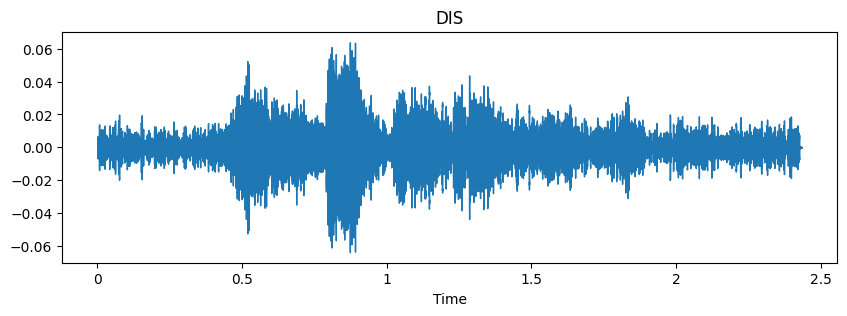

In [ ]:
plt.figure(figsize=(10, 3))
librosa.display.waveshow(signal, sr=sr)
plt.title(df['emotion'][0])
plt.show()

ipd.Audio(signal, rate=sr)

# Feature Engineering

In [ ]:
mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=40)
mfcc.shape

(40, 77)

In [ ]:
mfcc_mean = mfcc.mean(axis=1)
mfcc_mean.shape

(40,)

In [ ]:
def extract_features(file_name):
    file = os.path.join(audio_path, file_name)
    signal, sr = librosa.load(file, sr=16000)
    mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=40)
    return mfcc.mean(axis=1)

In [ ]:
extract_features(df['file_name'][0])

array([-3.8496713e+02,  8.6886192e+01,  5.5614029e+01,  2.9426422e+01,
        2.1344625e+01,  4.4971049e-01, -4.7594357e+00, -3.9233298e+00,
       -1.0301815e+00,  3.6489210e-01, -5.0503221e+00,  2.5607855e+00,
       -2.0368986e+00, -6.0365348e+00, -4.6470575e+00, -2.3322825e+00,
       -6.9031262e+00, -3.9387469e+00, -2.4330099e+00, -2.1076717e+00,
        1.0699854e+00,  4.1216871e-01,  9.8477453e-01,  3.7245278e+00,
       -6.7146504e-01,  1.0558944e+00, -1.0470659e+00,  2.4945326e-01,
       -1.7720824e-01,  3.5055423e+00,  2.2045901e+00,  6.2085891e-01,
        2.0970097e+00, -2.1656374e-02, -1.2934059e+00,  1.1226339e+00,
        1.1666516e+00,  1.2813661e+00,  1.4659691e+00, -1.2560077e+00],
      dtype=float32)

In [ ]:
features = []

for file_name in df['file_name']:
    features.append(extract_features(file_name))

len(features)

7442

# Preprocessing

In [ ]:
X = pd.DataFrame(features)
y = df['emotion']

X.shape, y.shape

((7442, 40), (7442,))

## Split by group

In [ ]:
SEED = 42

actors = df['actor'].unique()

actors_train_val, actors_test = train_test_split(actors, test_size=0.2, random_state=SEED)
actors_train, actors_val = train_test_split(actors_train_val, test_size=0.2, random_state=SEED)

In [ ]:
train_mask = df['actor'].isin(actors_train)
val_mask = df['actor'].isin(actors_val)
test_mask = df['actor'].isin(actors_test)

X_train_grp, y_train_grp = X[train_mask], y[train_mask]
X_val_grp, y_val_grp = X[val_mask], y[val_mask]
X_test_grp, y_test_grp = X[test_mask], y[test_mask]

len(X_train_grp), len(X_val_grp), len(X_test_grp)

(4654, 1230, 1558)

## Split randomly

In [ ]:
X_train_val, X_test_rnd, y_train_val, y_test_rnd = train_test_split(X, y, test_size=0.2, random_state=SEED)
X_train_rnd, X_val_rnd, y_train_rnd, y_val_rnd = train_test_split(X_train_val, y_train_val, test_size=0.2, random_state=SEED)

len(X_train_rnd), len(X_val_rnd), len(X_test_rnd)

(4762, 1191, 1489)

# Model

In [ ]:
y_val_rnd.value_counts(normalize=True).max()

0.18387909319899245

## On the random splitting

In [ ]:
# Step1: init
rf_rnd = RandomForestClassifier(random_state=SEED)

# Step2: fit
rf_rnd.fit(X_train_rnd, y_train_rnd)

# Step3: predict
y_pred_rnd = rf_rnd.predict(X_val_rnd)
accuracy_score(y_val_rnd, y_pred_rnd)

0.434928631402183

## On the grouped splitting

In [ ]:
rf_grp = RandomForestClassifier(random_state=SEED)

rf_grp.fit(X_train_grp, y_train_grp)

y_pred_grp = rf_grp.predict(X_val_grp)
accuracy_score(y_val_grp, y_pred_grp)

0.42032520325203254

# Error Analysis

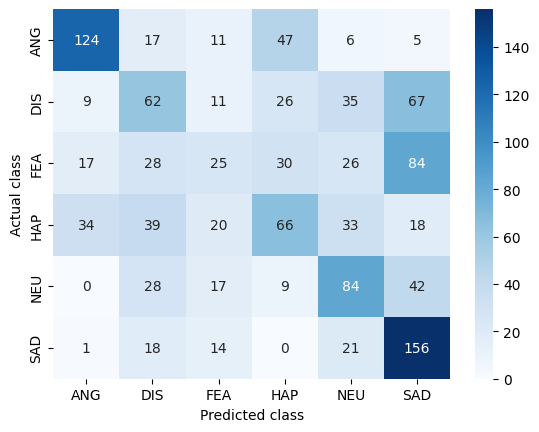

In [ ]:
conf_matrix = confusion_matrix(y_val_grp, y_pred_grp, labels=rf_grp.classes_)

sns.heatmap(conf_matrix, cmap=plt.cm.Blues, annot=True, fmt='d',
            xticklabels=rf_grp.classes_,
            yticklabels=rf_grp.classes_)

plt.xlabel('Predicted class')
plt.ylabel('Actual class');

In [ ]:
print(classification_report(y_val_grp, y_pred_grp))

              precision    recall  f1-score   support

         ANG       0.67      0.59      0.63       210
         DIS       0.32      0.30      0.31       210
         FEA       0.26      0.12      0.16       210
         HAP       0.37      0.31      0.34       210
         NEU       0.41      0.47      0.44       180
         SAD       0.42      0.74      0.54       210

    accuracy                           0.42      1230
   macro avg       0.41      0.42      0.40      1230
weighted avg       0.41      0.42      0.40      1230



# The test data

In [ ]:
y_pred_test = rf_grp.predict(X_test_grp)
accuracy_score(y_test_grp, y_pred_test)

0.43709884467265725

# Save the model

In [ ]:
import joblib
joblib.dump(rf_grp, 'emotion_model.pkl')

['emotion_model.pkl']